In [52]:
from scipy.io import loadmat
from scipy import sparse
import numpy as np
import matplotlib.pyplot as plt


loaded_companies = loadmat("Companies.mat")
companies = loaded_companies["Companies"]

# print(companies)
print(type(companies))
# print(companies.shape)
# print(companies.dtype)
# print(companies[:5])

X = companies[:, [0, 1, 3, 4, 5]]
y = companies[:, 2]

A = np.column_stack((np.ones(len(X)), X))

# print(X.shape)
# print(y.shape)
# print(A.shape)

print(A.shape)
print((A.T @ A).shape)
print((A.T @ y).shape)

# NORMAL EQUATIONS
beta_normal = np.linalg.solve(
    A.T @ A,
    A.T @ y
)

print(beta_normal)

<class 'numpy.ndarray'>
(79, 6)
(6, 6)
(6,)
[-9.56041633e+02  9.55827431e-02  2.99486396e-01  1.12522573e+01
 -4.77147000e-01  6.29761046e+00]


In [53]:
# QR
Q, R = np.linalg.qr(A, mode="reduced")
beta_qr = np.linalg.solve(
    R,
    Q.T @ y
)

print(beta_qr)

[-9.56041633e+02  9.55827431e-02  2.99486396e-01  1.12522573e+01
 -4.77147000e-01  6.29761046e+00]


In [54]:
# SVD
U, s, Vt = np.linalg.svd(A, full_matrices=False)

print(U.shape)
print(s.shape)
print(Vt.shape)

beta_svd = Vt.T @ ((U.T @ y) / s)

print(beta_svd)

(79, 6)
(6,)
(6, 6)
[-9.56041633e+02  9.55827431e-02  2.99486396e-01  1.12522573e+01
 -4.77147000e-01  6.29761046e+00]


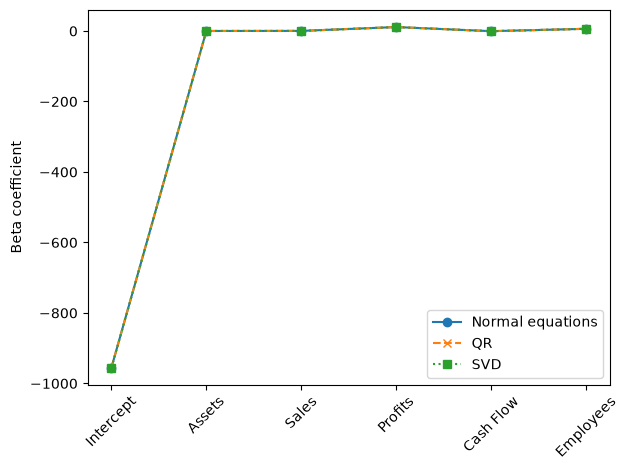

In [55]:
labels = ["Intercept", "Assets", "Sales", "Profits", "Cash Flow", "Employees"]
x = np.arange(len(labels))

plt.plot(x, beta_normal, "o-", label="Normal equations")
plt.plot(x, beta_qr, "x--", label="QR")
plt.plot(x, beta_svd, "s:", label="SVD")

plt.xticks(x, labels, rotation=45)
plt.ylabel("Beta coefficient")
plt.legend()
plt.tight_layout()
plt.show()

beta_qr = [-9.56041633e+02  9.55827431e-02  2.99486396e-01  1.12522573e+01
 -4.77147000e-01  6.29761046e+00]
R^2 = 0.9642574305702856


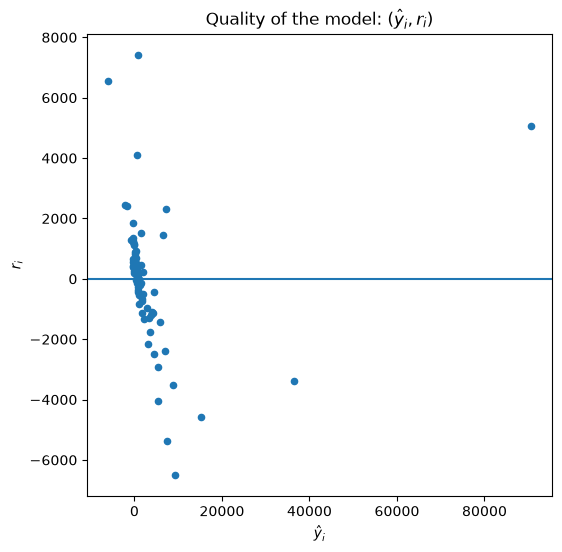

In [56]:
import numpy as np
import matplotlib.pyplot as plt

# predictors and response
X = companies[:, [0, 1, 3, 4, 5]]
y = companies[:, 2]

# design matrix [1, X]
A = np.column_stack((np.ones(len(X)), X))

# QR solution
Q, R = np.linalg.qr(A, mode="reduced")
beta_qr = np.linalg.solve(R, Q.T @ y)

# fitted values and residuals
y_hat = A @ beta_qr
r = y - y_hat

# R^2
R2 = 1 - np.sum(r**2) / np.sum((y - y.mean())**2)
print("beta_qr =", beta_qr)
print("R^2 =", R2)

# plot (ŷ_i, r_i)
plt.figure(figsize=(6, 6))
plt.scatter(y_hat, r, s=20)
plt.xlabel(r'$\hat{y}_i$')
plt.ylabel(r'$r_i$')
plt.title('Quality of the model: $(\\hat{y}_i, r_i)$')
plt.axhline(0)
plt.show()

beta_qr without GE and IBM = [ 1.00608378e+02  9.34577401e-02 -1.99434770e-01 -3.07107528e+00
  4.38527006e+00  3.48886207e+01]
R^2 without GE and IBM = 0.7238397414537843


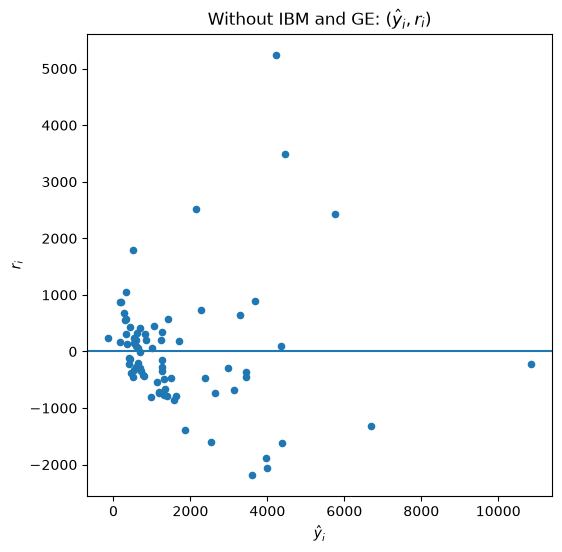

In [57]:
# remove General Electric and IBM
mask = np.ones(len(companies), dtype=bool)
mask[[32, 39]] = False

companies2 = companies[mask]

X2 = companies2[:, [0, 1, 3, 4, 5]]
y2 = companies2[:, 2]
A2 = np.column_stack((np.ones(len(X2)), X2))

Q2, R2_mat = np.linalg.qr(A2, mode="reduced")
beta_qr2 = np.linalg.solve(R2_mat, Q2.T @ y2)

y_hat2 = A2 @ beta_qr2
r2 = y2 - y_hat2

R2_2 = 1 - np.sum(r2**2) / np.sum((y2 - y2.mean())**2)
print("beta_qr without GE and IBM =", beta_qr2)
print("R^2 without GE and IBM =", R2_2)
plt.figure(figsize=(6, 6))
plt.scatter(y_hat2, r2, s=20)
plt.xlabel(r'$\hat{y}_i$')
plt.ylabel(r'$r_i$')
plt.title('Without IBM and GE: $(\\hat{y}_i, r_i)$')
plt.axhline(0)
plt.show()

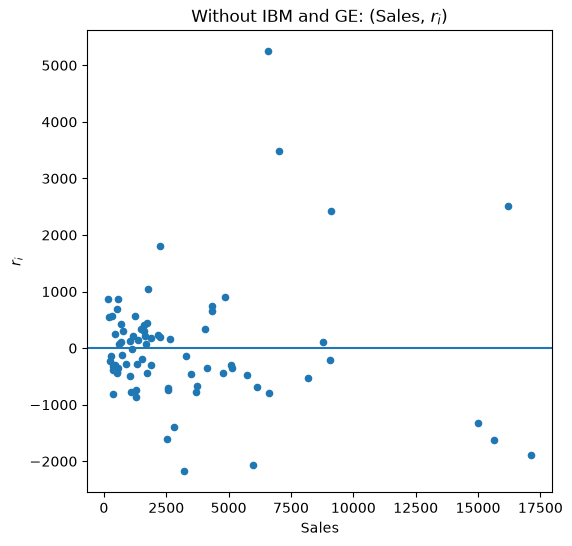

In [58]:
plt.figure(figsize=(6, 6))
plt.scatter(X2[:, 1], r2, s=20)
plt.xlabel('Sales')
plt.ylabel(r'$r_i$')
plt.title('Without IBM and GE: (Sales, $r_i$)')
plt.axhline(0)
plt.show()

In [59]:
# Ex 2
# Last company = FW Woolworth
woolworth = companies[-1]

# All companies except FW Woolworth
companies_new = companies[:-1]
X_new = companies_new[:, [0, 1, 3, 4, 5]]
y_new = companies_new[:, 2]

A_new = np.column_stack((np.ones(len(X_new)), X_new))

Q, R = np.linalg.qr(A_new, mode="reduced")

beta_new = np.linalg.solve(
    R,
    Q.T @ y_new
)

print(beta_new)
print(woolworth)
x_woolworth = woolworth[[0, 1, 3, 4, 5]]

x_woolworth_design = np.insert(x_woolworth, 0, 1)

y_pred_woolworth = x_woolworth_design @ beta_new

print(y_pred_woolworth)

[-9.47107877e+02  9.63100207e-02  2.79305982e-01  1.12433163e+01
 -4.92963685e-01  9.06586893e+00]
[2535.  5958.  1921.   177.   288.   118.1]
3879.9156245609934


In [60]:
loaded_a_med = loadmat("A_med.mat")
loaded_dict_med = loadmat("dict_med.mat")

# print(loaded_a_med.keys())
# print(loaded_dict_med.keys())

A_med = loaded_a_med["A_med"]
dict_med = loaded_dict_med["dict_med"]

# print(type(A_med))
# print(A_med.shape)
# print(A_med.dtype)

# print(type(dict_med))
# print(dict_med.shape)
# print(dict_med.dtype)

#print(A_med[:, 0])

print(A_med)
print("Nonzero values:", A_med.nnz)

<Compressed Sparse Column sparse matrix of dtype 'float64'
	with 51174 stored elements and shape (5735, 1033)>
  Coords	Values
  (73, 0)	1.0
  (340, 0)	1.0
  (885, 0)	2.0
  (901, 0)	1.0
  (1124, 0)	3.0
  (1125, 0)	1.0
  (1307, 0)	3.0
  (1333, 0)	2.0
  (1386, 0)	1.0
  (1963, 0)	1.0
  (1993, 0)	6.0
  (1998, 0)	3.0
  (2118, 0)	1.0
  (2207, 0)	4.0
  (2975, 0)	4.0
  (2976, 0)	4.0
  (2999, 0)	1.0
  (3158, 0)	6.0
  (3527, 0)	1.0
  (3866, 0)	3.0
  (4382, 0)	1.0
  (4795, 0)	1.0
  (4830, 0)	1.0
  (4843, 0)	1.0
  (4845, 0)	1.0
  :	:
  (3725, 1032)	1.0
  (3732, 1032)	2.0
  (3733, 1032)	1.0
  (4024, 1032)	2.0
  (4025, 1032)	1.0
  (4087, 1032)	1.0
  (4134, 1032)	2.0
  (4161, 1032)	1.0
  (4227, 1032)	1.0
  (4347, 1032)	1.0
  (4371, 1032)	1.0
  (4596, 1032)	1.0
  (4750, 1032)	1.0
  (4751, 1032)	4.0
  (4906, 1032)	1.0
  (4921, 1032)	1.0
  (5022, 1032)	2.0
  (5023, 1032)	1.0
  (5086, 1032)	1.0
  (5233, 1032)	1.0
  (5235, 1032)	1.0
  (5406, 1032)	1.0
  (5530, 1032)	1.0
  (5575, 1032)	2.0
  (5682, 1032)	1

/var/folders/sy/50gk3zw177g4529p4qy2310c0000gp/T/ipykernel_30587/1039779802.py:1: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
        That means the default return type will be a sparse array.
        Unless you use * instead of @, ** for matrix power, or you depend
        on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
        See the spmatrix to sparray migration guide for details.
        https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
        
  loaded_a_med = loadmat("A_med.mat")


In [61]:
first_document = A_med[:, 0]

print(first_document)
print("Nonzero words:", first_document.nnz)

<Compressed Sparse Column sparse matrix of dtype 'float64'
	with 26 stored elements and shape (5735, 1)>
  Coords	Values
  (73, 0)	1.0
  (340, 0)	1.0
  (885, 0)	2.0
  (901, 0)	1.0
  (1124, 0)	3.0
  (1125, 0)	1.0
  (1307, 0)	3.0
  (1333, 0)	2.0
  (1386, 0)	1.0
  (1963, 0)	1.0
  (1993, 0)	6.0
  (1998, 0)	3.0
  (2118, 0)	1.0
  (2207, 0)	4.0
  (2975, 0)	4.0
  (2976, 0)	4.0
  (2999, 0)	1.0
  (3158, 0)	6.0
  (3527, 0)	1.0
  (3866, 0)	3.0
  (4382, 0)	1.0
  (4795, 0)	1.0
  (4830, 0)	1.0
  (4843, 0)	1.0
  (4845, 0)	1.0
  (5014, 0)	1.0
Nonzero words: 26


In [62]:
print(dict_med[:10])

['14th                   ' '17b                    '
 '18th                   ' '19th                   '
 '1st                    ' '22nd                   '
 '2nd                    ' '3rd                    '
 '4th                    ' '5th                    ']


In [63]:
first_doc = A_med[:, 0]

word_indices = first_doc.nonzero()[0]
counts = first_doc[word_indices, 0].toarray().ravel()

print(word_indices)
print(counts)

[  73  340  885  901 1124 1125 1307 1333 1386 1963 1993 1998 2118 2207
 2975 2976 2999 3158 3527 3866 4382 4795 4830 4843 4845 5014]
[1. 1. 2. 1. 3. 1. 3. 2. 1. 1. 6. 3. 1. 4. 4. 4. 1. 6. 1. 3. 1. 1. 1. 1.
 1. 1.]


In [64]:
words = dict_med.ravel()
doc_words = words[word_indices]

print(doc_words)

['acids                  ' 'appears                '
 'coefficients           ' 'collected              '
 'correlation            ' 'correlations           '
 'delivery               ' 'dependent              '
 'determined             ' 'fatty                  '
 'fetal                  ' 'ffa                    '
 'free                   ' 'glucose                '
 'level                  ' 'levels                 '
 'lines                  ' 'maternal               '
 'obtained               ' 'plasma                 '
 'regression             ' 'significant            '
 'size                   ' 'slightly               '
 'slopes                 ' 'strongly               ']


In [65]:
for word, count in zip(doc_words, counts):
    print(word, count)

acids                   1.0
appears                 1.0
coefficients            2.0
collected               1.0
correlation             3.0
correlations            1.0
delivery                3.0
dependent               2.0
determined              1.0
fatty                   1.0
fetal                   6.0
ffa                     3.0
free                    1.0
glucose                 4.0
level                   4.0
levels                  4.0
lines                   1.0
maternal                6.0
obtained                1.0
plasma                  3.0
regression              1.0
significant             1.0
size                    1.0
slightly                1.0
slopes                  1.0
strongly                1.0


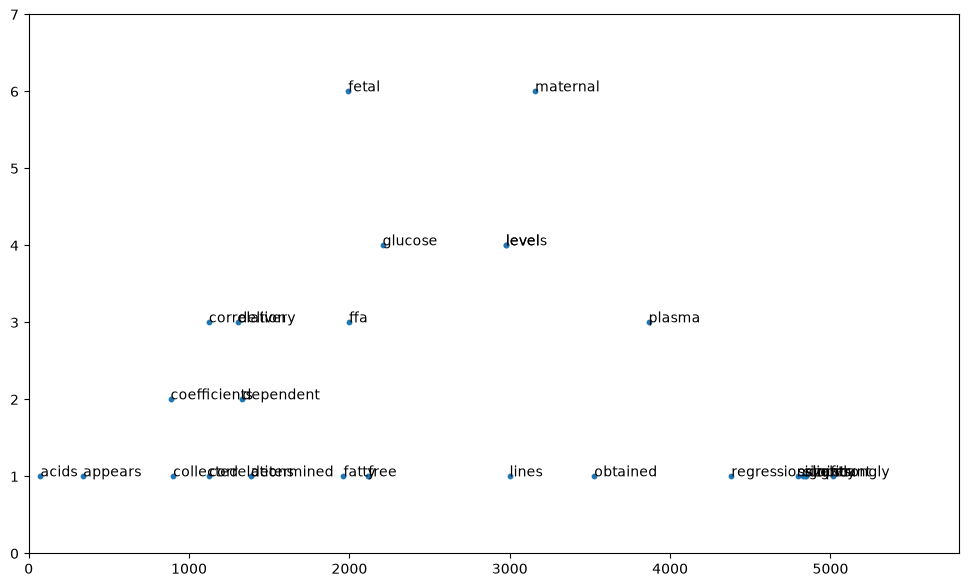

In [66]:
plt.figure(figsize=(12, 7))

# Plot dictionary index against occurrence count
plt.scatter(word_indices, counts, s=10)

# Add the corresponding word next to each point
for index, count, word in zip(word_indices, counts, doc_words):
    plt.annotate(
        word,
        (index, count),
    )

plt.xlim(0, 5800)
plt.ylim(0, 7)

plt.show()

In [70]:
# Ex 4
y = A_med[:, 0].toarray().ravel()

# X = remaining documents
X = A_med[:, 1:]

# Add intercept column
ones = sparse.csc_matrix(np.ones((A_med.shape[0], 1)))
A = sparse.hstack((ones, X), format="csc")

def cgls(A, b, tol=1e-8, max_iter=1000):
    n = A.shape[1]
    x = np.zeros(n)
    r = b - A @ x
    s = A.T @ r
    p = s.copy()
    gamma = s @ s
    
    b_norm = np.linalg.norm(b)
    s0_norm = np.linalg.norm(s)

    residual_history = [np.linalg.norm(r) / b_norm]

    for k in range(max_iter):
        q = A @ p
        alpha = gamma / (q @ q)
        x = x + alpha * p
        r = r - alpha * q
        residual_history.append(
            np.linalg.norm(r) / b_norm
        )
        
        s = A.T @ r

        if np.linalg.norm(s) / s0_norm < tol:
            break

        gamma_new = s @ s

        beta = gamma_new / gamma
        p = s + beta * p

        gamma = gamma_new

    return x, residual_history

Iterations: 205


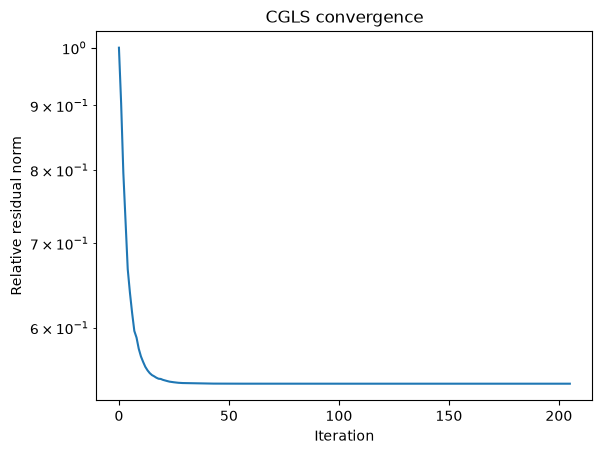

In [ ]:
beta_cgls, residual_history = cgls(A, y)

print("Iterations:", len(residual_history) - 1)

plt.semilogy(residual_history)
plt.xlabel("Iteration")
plt.ylabel("Relative residual norm")
plt.title("CGLS convergence")
plt.show()

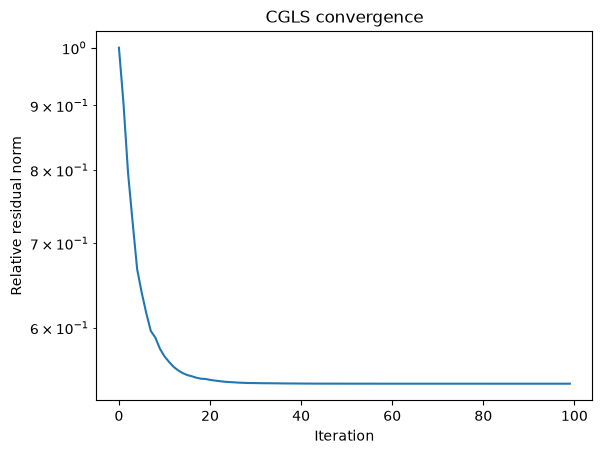

In [74]:
plt.semilogy(residual_history[:100])
plt.xlabel("Iteration")
plt.ylabel("Relative residual norm")
plt.title("CGLS convergence")
plt.show()